**Assignment 2 — Task 2: Model Tuning (Hyperparameter Optimisation)**

---

**1. Introduction**

In [1]:
import tensorflow as tf
print(tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

2.10.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
# ── Enable mixed precision (float16 compute, float32 accumulation) ───────────
from tensorflow.keras import mixed_precision

if tf.config.list_physical_devices('GPU'):
    mixed_precision.set_global_policy('mixed_float16')
    print(f"Mixed precision enabled — compute dtype: {mixed_precision.global_policy().compute_dtype}, "
          f"variable dtype: {mixed_precision.global_policy().variable_dtype}")
else:
    print("No GPU detected — staying on float32 (mixed precision only helps on GPU/TPU, "
          "and can be marginally slower on CPU-only environments).")

Your GPUs may run slowly with dtype policy mixed_float16 because they do not have compute capability of at least 7.0. Your GPUs:
  DML, no compute capability (probably not an Nvidia GPU) (x2)
See https://developer.nvidia.com/cuda-gpus for a list of GPUs and their compute capabilities.
If you will use compatible GPU(s) not attached to this host, e.g. by running a multi-worker model, you can ignore this warning. This message will only be logged once
Mixed precision enabled — compute dtype: float16, variable dtype: float32


In [3]:
# ── Install Keras Tuner if needed ─────────────────────────────────────────────
!pip install keras-tuner --quiet

import os, json, pickle, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers, callbacks, regularizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
import keras_tuner as kt

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

def get_search_time(var_name):
    return globals().get(var_name, None)

def fmt_minutes(seconds):
    return f"{seconds/60:.1f} min" if seconds is not None else "N/A (re-run the search cell above)"

def get_completed_trials(tuner, n=None):
    from keras_tuner.engine.trial import TrialStatus
    completed = [t for t in tuner.oracle.trials.values()
                 if t.status == TrialStatus.COMPLETED and t.score is not None]
    maximize = tuner.oracle.objective.direction == 'max'
    completed.sort(key=lambda t: t.score, reverse=maximize)
    return completed[:n] if n else completed

print(f"TensorFlow   : {tf.__version__}")
print(f"Keras Tuner  : {kt.__version__}")

TensorFlow   : 2.10.0
Keras Tuner  : 1.4.8


In [4]:
# ── QUICK TEST MODE — flip to True for a fast local CPU smoke test ───────────
QUICK_TEST = False

if QUICK_TEST:
    print("QUICK_TEST is ON — this run will NOT produce a usable tuned model, "
          "it only verifies the code executes without errors.")

In [5]:
# ── Load config ───────────────────────────────────────────────────────────────
with open('dataset_config.json') as f:
    cfg = json.load(f)

TRAIN_DIR    = cfg['TRAIN_DIR']
VAL_DIR      = cfg['VAL_DIR']
IMG_SIZE     = tuple(cfg['IMG_SIZE']) if not QUICK_TEST else (64, 64)
N_CLASSES    = cfg['N_CLASSES']
CLASSES      = cfg['CLASSES']
CLASS_WEIGHTS = {int(k): v for k, v in cfg['CLASS_WEIGHTS'].items()}
BATCH_SIZE   = cfg['BATCH_SIZE']

if QUICK_TEST:
    print(f"QUICK_TEST: IMG_SIZE overridden to {IMG_SIZE} (real config: {tuple(cfg['IMG_SIZE'])})")

# Data generators
train_datagen = ImageDataGenerator(
    rescale=1./255, rotation_range=20, width_shift_range=0.15,
    height_shift_range=0.15, shear_range=0.1, zoom_range=0.2,
    horizontal_flip=True, brightness_range=[0.8, 1.2], fill_mode='nearest'
)
val_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', seed=SEED, shuffle=True
)
val_gen = val_datagen.flow_from_directory(
    VAL_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', seed=SEED, shuffle=False
)
print("Data ready.")

Found 30000 images belonging to 15 classes.
Found 2000 images belonging to 15 classes.
Data ready.


---
**2. Hyperparameter Tuning — Custom CNN**

*2.1 Search Space*

In [6]:
# ── Tunable Custom CNN builder function ──────────────────────────────────────
def cnn_model_builder(hp):
    """Keras Tuner model builder for Custom CNN."""
    inp = keras.Input(shape=(*IMG_SIZE, 3))
    x = inp

    init_filters         = hp.Choice('init_filters', values=[32, 64])
    l2_reg                = hp.Float('l2_reg', min_value=1e-4, max_value=1e-2, sampling='log')
    activation             = hp.Choice('activation', values=['relu', 'swish'])
    use_spatial_dropout    = hp.Boolean('use_spatial_dropout')

    for i, multiplier in enumerate([1, 2, 4, 8]):
        filters = init_filters * multiplier
        x = layers.Conv2D(filters, (3,3), padding='same',
                          kernel_regularizer=regularizers.l2(l2_reg))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation(activation)(x)
        x = layers.Conv2D(filters, (3,3), padding='same',
                          kernel_regularizer=regularizers.l2(l2_reg))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation(activation)(x)
        x = layers.MaxPooling2D(2, 2)(x)
        drop = hp.Float(f'dropout_{i}', min_value=0.1, max_value=0.4, step=0.1)
        if use_spatial_dropout:
            x = layers.SpatialDropout2D(drop)(x)   # preserves spatial structure (Lecture 09)
        else:
            x = layers.Dropout(drop)(x)

    x = layers.GlobalAveragePooling2D()(x)

    dense_units = hp.Choice('dense_units', values=[256, 512, 1024])
    x = layers.Dense(dense_units, activation=activation,
                     kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    final_drop = hp.Float('final_dropout', min_value=0.3, max_value=0.6, step=0.1)
    x = layers.Dropout(final_drop)(x)
    # Output layer stays float32 even under mixed precision, for numerically
    # stable softmax + loss computation.
    out = layers.Dense(N_CLASSES, activation='softmax', dtype='float32')(x)

    model = keras.Model(inp, out)

    lr = hp.Float('learning_rate', min_value=1e-5, max_value=1e-2, sampling='log')
    optimizer_choice = hp.Choice('optimizer', values=['adam', 'rmsprop', 'sgd'])
    if optimizer_choice == 'adam':
        optimizer = optimizers.Adam(learning_rate=lr)
    elif optimizer_choice == 'rmsprop':
        optimizer = optimizers.RMSprop(learning_rate=lr)
    else:
        sgd_momentum = hp.Float('sgd_momentum', min_value=0.0, max_value=0.9, step=0.1)
        optimizer = optimizers.SGD(learning_rate=lr, momentum=sgd_momentum)

    model.compile(
        optimizer=optimizer,
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

*2.2 Hyperband Search (Adaptive / Bandit-Based)*

In [7]:
# ── Hyperband tuner for CNN ───────────────────────────────────────────────────
cnn_tuner_hyperband = kt.Hyperband(
    cnn_model_builder,
    objective        = 'val_accuracy',
    max_epochs       = 2,
    factor           = 4,
    directory        = 'kt_cnn_hyperband',
    project_name     = 'custom_cnn_hyperband',
    seed             = SEED,
    overwrite        = True
)

cnn_tuner_hyperband.search_space_summary()

stop_early = callbacks.EarlyStopping(monitor='val_loss', patience=5)

print("\nStarting Hyperband search for Custom CNN...")
t0 = time.time()
try:
    cnn_tuner_hyperband.search(
        train_gen,
        epochs          = 2,
        validation_data = val_gen,
        callbacks       = [stop_early],
        class_weight    = CLASS_WEIGHTS,
        verbose         = 1
    )
except KeyboardInterrupt:
    print("\nSearch interrupted by user — continuing with whatever trials completed so far.")
hyperband_search_time = time.time() - t0

n_hb_trials = len(get_completed_trials(cnn_tuner_hyperband))
if n_hb_trials == 0:
    raise RuntimeError(
        "No Hyperband trials finished before the interrupt (the one in progress "
        "doesn't count) — there's nothing usable yet. Re-run this cell and let "
        "at least one trial complete fully before interrupting."
    )
print(f"\nHyperband search for CNN complete in {fmt_minutes(hyperband_search_time)} "
      f"({n_hb_trials} completed trial(s)).")

Trial 2 Complete [00h 38m 04s]
val_accuracy: 0.33650001883506775

Best val_accuracy So Far: 0.33650001883506775
Total elapsed time: 01h 11m 34s

Hyperband search for CNN complete in 71.6 min (2 completed trial(s)).


*2.3 Random Search (Zero-Order / Direct Search Baseline — Lecture 03)*

In [8]:
# ── Random Search tuner for CNN — a baseline comparison ───────────────────────
RANDOM_SEARCH_TRIALS = 2 
RANDOM_SEARCH_EPOCHS = 2    # fixed budget per trial (Random Search has no adaptive allocation)

cnn_tuner_random = kt.RandomSearch(
    cnn_model_builder,
    objective        = 'val_accuracy',
    max_trials       = RANDOM_SEARCH_TRIALS,
    directory        = 'kt_cnn_random',
    project_name     = 'custom_cnn_random_search',
    seed             = SEED,
    overwrite        = True
)

print(f"Starting Random Search for Custom CNN ({RANDOM_SEARCH_TRIALS} trials)...")
print("(Safe to interrupt early if it's taking too long — same as above.)")
t0 = time.time()
try:
    cnn_tuner_random.search(
        train_gen,
        epochs          = RANDOM_SEARCH_EPOCHS,
        validation_data = val_gen,
        callbacks       = [callbacks.EarlyStopping(monitor='val_loss', patience=5)],
        class_weight    = CLASS_WEIGHTS,
        verbose         = 1
    )
except KeyboardInterrupt:
    print("\nSearch interrupted by user — continuing with whatever trials completed so far.")
random_search_time = time.time() - t0

n_rs_trials = len(get_completed_trials(cnn_tuner_random))
if n_rs_trials == 0:
    raise RuntimeError(
        "No Random Search trials finished before the interrupt (the one in "
        "progress doesn't count) — there's nothing usable yet. Re-run this cell "
        "and let at least one trial complete fully before interrupting."
    )
print(f"\nRandom Search for CNN complete in {fmt_minutes(random_search_time)} "
      f"({n_rs_trials} completed trial(s)).")

Trial 2 Complete [00h 40m 10s]
val_accuracy: 0.39250001311302185

Best val_accuracy So Far: 0.39250001311302185
Total elapsed time: 01h 13m 47s

Random Search for CNN complete in 73.8 min (2 completed trial(s)).


*2.4 Select the Winning Strategy & Retrain*

In [9]:
# ── Compare Hyperband vs Random Search, keep whichever found the better config ─
hyperband_search_time = get_search_time('hyperband_search_time')
random_search_time    = get_search_time('random_search_time')

hyperband_best_trial = get_completed_trials(cnn_tuner_hyperband, 1)[0]
random_best_trial    = get_completed_trials(cnn_tuner_random, 1)[0]

hyperband_best_score = hyperband_best_trial.score
random_best_score    = random_best_trial.score

print(f"Hyperband   — best val_accuracy: {hyperband_best_score:.4f}  "
      f"({len(get_completed_trials(cnn_tuner_hyperband))} completed trials, {fmt_minutes(hyperband_search_time)})")
print(f"Random Search — best val_accuracy: {random_best_score:.4f}  "
      f"({len(get_completed_trials(cnn_tuner_random))} completed trials, {fmt_minutes(random_search_time)})")

if hyperband_best_score >= random_best_score:
    winning_tuner_name = 'Hyperband'
    cnn_tuner = cnn_tuner_hyperband
    winning_trial = hyperband_best_trial
else:
    winning_tuner_name = 'Random Search'
    cnn_tuner = cnn_tuner_random
    winning_trial = random_best_trial

best_cnn_hp = winning_trial.hyperparameters
print(f"\n=> Winning strategy for Custom CNN: {winning_tuner_name}")
print("Best CNN Hyperparameters:")
for key, value in best_cnn_hp.values.items():
    print(f"  {key:20s}: {value}")

Hyperband   — best val_accuracy: 0.3365  (2 completed trials, 71.6 min)
Random Search — best val_accuracy: 0.3925  (2 completed trials, 73.8 min)

=> Winning strategy for Custom CNN: Random Search
Best CNN Hyperparameters:
  init_filters        : 64
  l2_reg              : 0.00015159319577885927
  activation          : swish
  use_spatial_dropout : False
  dropout_0           : 0.30000000000000004
  dropout_1           : 0.1
  dropout_2           : 0.2
  dropout_3           : 0.2
  dense_units         : 1024
  final_dropout       : 0.4
  learning_rate       : 0.00026820988917015964
  optimizer           : rmsprop


In [10]:
# ── Retrain best CNN with optimal HPs for full epochs ─────────────────────────
best_cnn_model = cnn_tuner.hypermodel.build(best_cnn_hp)

tuned_cnn_callbacks = [
    callbacks.EarlyStopping(monitor='val_loss', patience=10,
                            restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                patience=5, verbose=1),
    callbacks.ModelCheckpoint('best_tuned_cnn.keras', monitor='val_accuracy',
                              save_best_only=True),
    callbacks.ModelCheckpoint('latest_tuned_cnn.keras',
                              save_best_only=False,
                              verbose=0)
]

history_tuned_cnn = best_cnn_model.fit(
    train_gen, epochs=3, validation_data=val_gen,
    callbacks=tuned_cnn_callbacks, class_weight=CLASS_WEIGHTS, verbose=1
)

print(f"Best val_accuracy after tuning: "
      f"{max(history_tuned_cnn.history['val_accuracy']):.4f}")
best_cnn_model.save('model_tuned_cnn.keras')

Epoch 1/3
938/938 [==============================] - 1339s 1s/step - loss: 2.7709 - accuracy: 0.2653 - val_loss: 2.5458 - val_accuracy: 0.3375 - lr: 2.6821e-04
Epoch 2/3
938/938 [==============================] - 1434s 2s/step - loss: 2.1478 - accuracy: 0.4212 - val_loss: 2.8843 - val_accuracy: 0.3710 - lr: 2.6821e-04
Epoch 3/3
938/938 [==============================] - 1467s 2s/step - loss: 1.8396 - accuracy: 0.5050 - val_loss: 2.9334 - val_accuracy: 0.3800 - lr: 2.6821e-04
Best val_accuracy after tuning: 0.3800


---
**3. Hyperparameter Tuning — ResNet50 (Bayesian Optimisation)**

*3.1 Bayesian Optimisation Strategy*

In [11]:
# ── Tunable ResNet50 builder function ────────────────────────────────────────
def resnet_model_builder(hp):
    base = ResNet50(include_top=False, weights='imagenet',
                    input_shape=(*IMG_SIZE, 3))

    unfreeze_layers = hp.Int('unfreeze_layers', min_value=0, max_value=100, step=20)
    if unfreeze_layers == 0:
        base.trainable = False
    else:
        base.trainable = True
        for layer in base.layers[:-unfreeze_layers]:
            layer.trainable = False

    inp  = keras.Input(shape=(*IMG_SIZE, 3))
    x    = tf.keras.applications.resnet50.preprocess_input(inp * 255.0)
    x    = base(x, training=(unfreeze_layers > 0))
    x    = layers.GlobalAveragePooling2D()(x)

    # Fixed (not tuned) — reasonable defaults for the classification head
    DENSE_UNITS_FIXED = 256
    L2_REG_FIXED       = 1e-4
    x = layers.Dense(DENSE_UNITS_FIXED, activation='relu',
                     kernel_regularizer=regularizers.l2(L2_REG_FIXED))(x)
    x = layers.BatchNormalization()(x)
    drop = hp.Float('dropout', min_value=0.2, max_value=0.6, step=0.1)
    x = layers.Dropout(drop)(x)
    out = layers.Dense(N_CLASSES, activation='softmax', dtype='float32')(x)

    model = keras.Model(inp, out)
    lr = hp.Float('learning_rate', min_value=1e-5, max_value=1e-3, sampling='log')
    model.compile(
        optimizer=optimizers.Adam(learning_rate=lr),   # fixed — Adam suits fine-tuning well here
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

In [12]:
# ── Bayesian Optimisation tuner for ResNet50 ──────────────────────────────────
resnet_tuner = kt.BayesianOptimization(
    resnet_model_builder,
    objective    = 'val_accuracy',
    max_trials   = 2,
    num_initial_points = 2,
    directory    = 'kt_resnet',
    project_name = 'resnet_tuning_v2',
    seed         = SEED,
    overwrite    = True
)

resnet_tuner.search_space_summary()

stop_early_resnet = callbacks.EarlyStopping(monitor='val_loss', patience=5)

print("\nStarting Bayesian Optimisation search for ResNet50...")
t0 = time.time()
try:
    resnet_tuner.search(
        train_gen, epochs=2, validation_data=val_gen,
        callbacks=[stop_early_resnet], class_weight=CLASS_WEIGHTS, verbose=1
    )
except KeyboardInterrupt:
    print("\nSearch interrupted by user — continuing with whatever trials completed so far.")
bayesian_search_time = time.time() - t0

n_bo_trials = len(get_completed_trials(resnet_tuner))
if n_bo_trials == 0:
    raise RuntimeError(
        "No Bayesian trials finished before the interrupt (the one in progress "
        "doesn't count) — there's nothing usable yet. Re-run this cell and let "
        "at least one trial complete fully before interrupting."
    )
print(f"\nBayesian search for ResNet50 complete in {fmt_minutes(bayesian_search_time)} "
      f"({n_bo_trials} completed trial(s)).")

Trial 2 Complete [00h 14m 48s]
val_accuracy: 0.4975000321865082

Best val_accuracy So Far: 0.4975000321865082
Total elapsed time: 00h 29m 35s

Bayesian search for ResNet50 complete in 29.6 min (2 completed trial(s)).


In [13]:
# ── Best ResNet50 hyperparameters ─────────────────────────────────────────────
best_resnet_trial = get_completed_trials(resnet_tuner, 1)[0]
best_resnet_hp = best_resnet_trial.hyperparameters

print("Best ResNet50 Hyperparameters:")
for key, value in best_resnet_hp.values.items():
    print(f"  {key:20s}: {value}")

Best ResNet50 Hyperparameters:
  unfreeze_layers     : 20
  dropout             : 0.5
  learning_rate       : 5.0546665575067195e-05


In [14]:
# ── Retrain best ResNet50 for full epochs ─────────────────────────────────────
best_resnet_model = resnet_tuner.hypermodel.build(best_resnet_hp)

tuned_resnet_callbacks = [
    callbacks.EarlyStopping(monitor='val_loss', patience=10,
                            restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                patience=5, verbose=1),
    callbacks.ModelCheckpoint('best_tuned_resnet.keras', monitor='val_accuracy',
                              save_best_only=True)
]

history_tuned_resnet = best_resnet_model.fit(
    train_gen, epochs=3, validation_data=val_gen,
    callbacks=tuned_resnet_callbacks, class_weight=CLASS_WEIGHTS, verbose=1
)

print(f"Best val_accuracy after tuning: "
      f"{max(history_tuned_resnet.history['val_accuracy']):.4f}")
best_resnet_model.save('model_tuned_resnet.keras')

Epoch 1/3
938/938 [==============================] - 459s 483ms/step - loss: 0.5674 - accuracy: 0.8516 - val_loss: 2.3713 - val_accuracy: 0.4615 - lr: 5.0547e-05
Epoch 2/3
938/938 [==============================] - 456s 486ms/step - loss: 0.2371 - accuracy: 0.9445 - val_loss: 2.3230 - val_accuracy: 0.4935 - lr: 5.0547e-05
Epoch 3/3
938/938 [==============================] - 423s 451ms/step - loss: 0.1874 - accuracy: 0.9579 - val_loss: 2.2960 - val_accuracy: 0.5185 - lr: 5.0547e-05
Best val_accuracy after tuning: 0.5185


---
**4. Tuning Results Summary**

In [15]:
# ── Top trials summary — all three search strategies ─────────────────────────
def show_top_trials(tuner, name, n=5):
    print(f"\n{'='*55}")
    print(f"  TOP {n} TRIALS — {name}")
    print(f"{'='*55}")
    completed = get_completed_trials(tuner, n)
    if not completed:
        print("  (no completed trials — search may have been interrupted very early)")
        return
    for i, trial in enumerate(completed):
        print(f"  Rank {i+1}  |  val_accuracy={trial.score:.4f}  |  "
              f"HP={trial.hyperparameters.values}")

show_top_trials(cnn_tuner_hyperband, 'Custom CNN (Hyperband)',              n=5)
show_top_trials(cnn_tuner_random,    'Custom CNN (Random Search baseline)', n=5)
show_top_trials(resnet_tuner,        'ResNet50 TL (Bayesian Optimisation)', n=5)


  TOP 5 TRIALS — Custom CNN (Hyperband)
  Rank 1  |  val_accuracy=0.3365  |  HP={'init_filters': 64, 'l2_reg': 0.00015159319577885927, 'activation': 'swish', 'use_spatial_dropout': False, 'dropout_0': 0.30000000000000004, 'dropout_1': 0.1, 'dropout_2': 0.2, 'dropout_3': 0.2, 'dense_units': 1024, 'final_dropout': 0.4, 'learning_rate': 0.00026820988917015964, 'optimizer': 'rmsprop', 'tuner/epochs': 2, 'tuner/initial_epoch': 0, 'tuner/bracket': 0, 'tuner/round': 0}
  Rank 2  |  val_accuracy=0.0895  |  HP={'init_filters': 64, 'l2_reg': 0.00011942731780421024, 'activation': 'relu', 'use_spatial_dropout': False, 'dropout_0': 0.4, 'dropout_1': 0.2, 'dropout_2': 0.30000000000000004, 'dropout_3': 0.1, 'dense_units': 512, 'final_dropout': 0.3, 'learning_rate': 0.008611217825990653, 'optimizer': 'rmsprop', 'tuner/epochs': 2, 'tuner/initial_epoch': 0, 'tuner/bracket': 0, 'tuner/round': 0}

  TOP 5 TRIALS — Custom CNN (Random Search baseline)
  Rank 1  |  val_accuracy=0.3925  |  HP={'init_filters'

*4.1 Search Strategy Comparison (Zero-Order vs Adaptive Methods — Lecture 03)*

                            Strategy  Best Val Acc  Trials Run  Search Time (min)
Random Search\n(zero-order / direct)         0.393           2             73.781
  Hyperband\n(adaptive bandit-based)         0.337           2             71.568


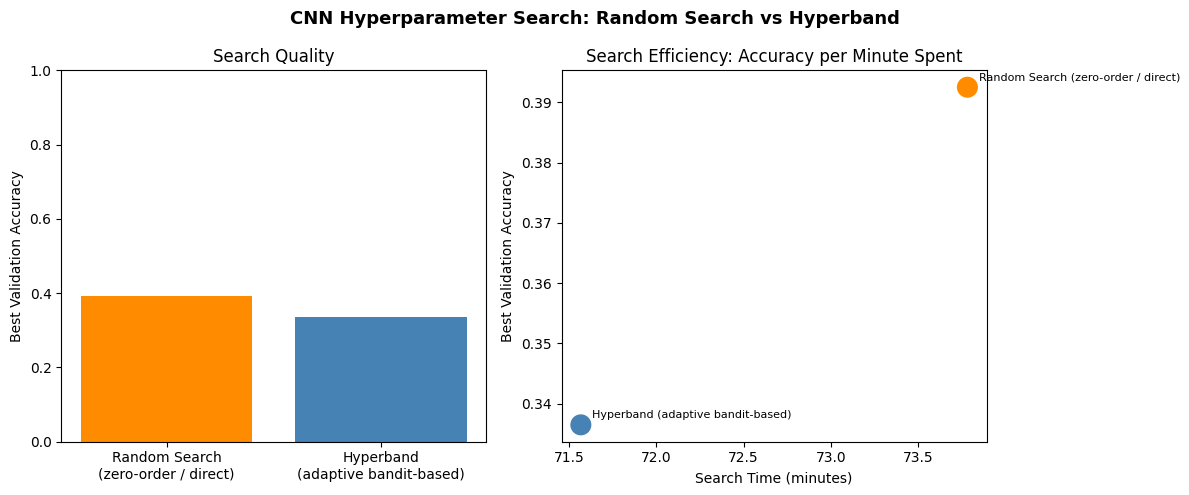


Hyperband's adaptive resource allocation found a config that was -0.0560 val_accuracy vs. Random Search's zero-order baseline, using 71.6 min vs 73.8 min of search time.


In [16]:
# ── Head-to-head: Hyperband vs Random Search, same model, same budget order ───
hyperband_search_time = get_search_time('hyperband_search_time')
random_search_time    = get_search_time('random_search_time')

strategy_comparison = pd.DataFrame({
    'Strategy'       : ['Random Search\n(zero-order / direct)', 'Hyperband\n(adaptive bandit-based)'],
    'Best Val Acc'   : [random_best_score, hyperband_best_score],
    'Trials Run'     : [len(get_completed_trials(cnn_tuner_random)), len(get_completed_trials(cnn_tuner_hyperband))],
    'Search Time (min)': [
        random_search_time / 60 if random_search_time is not None else np.nan,
        hyperband_search_time / 60 if hyperband_search_time is not None else np.nan,
    ],
})
print(strategy_comparison.to_string(index=False, float_format=lambda x: f'{x:.3f}'))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
colors = ['darkorange', 'steelblue']
axes[0].bar(strategy_comparison['Strategy'], strategy_comparison['Best Val Acc'], color=colors)
axes[0].set_ylabel('Best Validation Accuracy')
axes[0].set_title('Search Quality')
axes[0].set_ylim(0, 1.0)

if strategy_comparison['Search Time (min)'].notna().all():
    axes[1].scatter(strategy_comparison['Search Time (min)'], strategy_comparison['Best Val Acc'],
                     s=200, c=colors)
    for i, row in strategy_comparison.iterrows():
        axes[1].annotate(row['Strategy'].replace('\n', ' '),
                          (row['Search Time (min)'], row['Best Val Acc']),
                          textcoords="offset points", xytext=(8, 5), fontsize=8)
    axes[1].set_xlabel('Search Time (minutes)')
    axes[1].set_ylabel('Best Validation Accuracy')
    axes[1].set_title('Search Efficiency: Accuracy per Minute Spent')
else:
    axes[1].bar(strategy_comparison['Strategy'], strategy_comparison['Trials Run'], color=colors)
    axes[1].set_ylabel('Trials Run')
    axes[1].set_title('Search Volume (timing unavailable this session)')

plt.suptitle('CNN Hyperparameter Search: Random Search vs Hyperband', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('tuning_strategy_comparison.png', dpi=150)
plt.show()

acc_gain = hyperband_best_score - random_best_score
print(f"\nHyperband's adaptive resource allocation found a config that was "
      f"{acc_gain:+.4f} val_accuracy vs. Random Search's zero-order baseline, "
      f"using {fmt_minutes(hyperband_search_time)} vs {fmt_minutes(random_search_time)} of search time.")

*4.2 Before vs After Tuning — Accuracy Improvement*

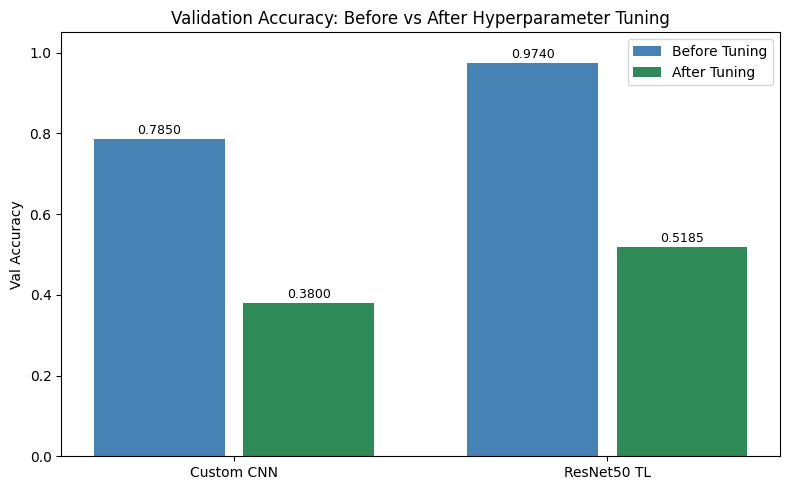

Custom CNN    improvement: -40.50 pp
ResNet50 TL   improvement: -45.55 pp


In [17]:
# ── Before vs After tuning comparison plot ────────────────────────────────────
try:
    with open('history_cnn.pkl',    'rb') as f: hist_cnn_base    = pickle.load(f)
    with open('history_resnet.pkl', 'rb') as f: hist_resnet_base = pickle.load(f)

    cnn_before    = max(hist_cnn_base['val_accuracy'])
    cnn_after     = max(history_tuned_cnn.history['val_accuracy'])
    resnet_before = max(hist_resnet_base['val_accuracy'])
    resnet_after  = max(history_tuned_resnet.history['val_accuracy'])

    models_names  = ['Custom CNN', 'ResNet50 TL']
    before_vals   = [cnn_before,    resnet_before]
    after_vals    = [cnn_after,     resnet_after]

    x = np.arange(len(models_names))
    fig, ax = plt.subplots(figsize=(8, 5))
    bars1 = ax.bar(x - 0.2, before_vals, 0.35, label='Before Tuning', color='steelblue')
    bars2 = ax.bar(x + 0.2, after_vals,  0.35, label='After Tuning',  color='seagreen')

    for bar in list(bars1) + list(bars2):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=9)

    ax.set_xticks(x)
    ax.set_xticklabels(models_names)
    ax.set_ylabel('Val Accuracy')
    ax.set_ylim(0, 1.05)
    ax.set_title('Validation Accuracy: Before vs After Hyperparameter Tuning')
    ax.legend()
    plt.tight_layout()
    plt.savefig('tuning_before_after.png', dpi=150)
    plt.show()

    print(f"Custom CNN    improvement: {(cnn_after - cnn_before)*100:+.2f} pp")
    print(f"ResNet50 TL   improvement: {(resnet_after - resnet_before)*100:+.2f} pp")
except FileNotFoundError:
    print("Baseline history files (history_cnn.pkl / history_resnet.pkl) not found — "
          "run A2_Task1 first if you want the before/after comparison.")

In [18]:
# ── Save tuned histories + strategy comparison for Task 3 ────────────────────
with open('history_tuned_cnn.pkl',    'wb') as f:
    pickle.dump(history_tuned_cnn.history, f)
with open('history_tuned_resnet.pkl', 'wb') as f:
    pickle.dump(history_tuned_resnet.history, f)

strategy_comparison.to_csv('task2_search_strategy_comparison.csv', index=False)

print("✓  Tuned models, histories, and strategy comparison saved for Task 3.")

✓  Tuned models, histories, and strategy comparison saved for Task 3.
